# MCDSS - MESIIA virtual group.    URV
# **TASK 2. Aggregation operators for numerical data**

The goal of this session is to practise with two simple methods of aggregation: WSM (Weighted Sum Model) that is equivalent to weighted average and afterwards the OWA operator (Ordered Weighted Average).
The exercise will also enable you to the use of Python notebooks and with *mcda library* using Python programming tools.

This exercise is part of the evaluation of the course.

**You must write a report on this exercise and upload it at Moodle before the indicated deadline. You must submit a PDF file that includes the results of each task indicated below. In addition to the results, you must add clear and detailed explanations about the results, including the observations and conclusions at each question.**

The decision problem we will consider is the selection of the best restaurant for a certain decision maker. We will consider different restaurants in Tarragona and 6 criteria.

The first thing we should do is installing the MCDA package. To do that, we use the `pip` command. Run the cell and test if everything went correctly. Take a look to the MCDA package documentation to know how to use it properly. [Documentation](https://py-mcda.readthedocs.io/en/stable/index.html) and [Examples](https://py-mcda.readthedocs.io/en/stable/examples.html)

We will use version `0.4.0`.

In [31]:
!pip install mcda==0.4.0

## Task 1: **Weighted Average or Weighted Sum**

1. The input data of this MCDA methods is: a list of alternatives, a list of criteria and the weights of the criteria. In this model, weights represent the relative importance of each criterion. The sum of the weights must be 1 unit.

In [32]:
import mcda
import pandas as pd
import numpy as np
import pandas as pd
from mcda.core.performance_table import *
from mcda.core.scales import *
from mcda.plot import *

alternatives = ["Terrat", "RacoAbat", "Dominos", "Ancora", "Frida", "Barhaus"]

# Criteria with its importance
criteria = {
    "Food": 0.3,
    "Personnel": 0.3,
    "Atmosphere": 0.1,
    "Category": 0.1,
    "Location": 0.1,
    "Terrace": 0.1
}
criteria

{'Food': 0.3,
 'Personnel': 0.3,
 'Atmosphere': 0.1,
 'Category': 0.1,
 'Location': 0.1,
 'Terrace': 0.1}

2. Here you have the performance table. Each row corresponds to one of the restaurants (alternatives) and each column contains the utility scores for the set of criteria. The range of the utility is 0..1 and all criteria are maximized.

In [33]:
# All criteria maximized means that higher utilities are better
performance_table = PerformanceTable(
    [[0.7, 0.9, 0.6, 0.9, 0.0, 0.4],
     [0.5, 0.7, 0.6, 0.7, 0.2, 0.0],
     [0.2, 0.3, 0.1, 0.2, 0.8, 0.0],
     [0.9, 0.5, 0.4, 0.3, 1.0, 0.7],
     [0.8, 0.7, 0.1, 0.5, 0.1, 0.4],
     [0.9, 1.0, 0.3, 0.8, 0.2, 1.0]],
    alternatives = alternatives,
    criteria = criteria.keys())

performance_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.7,0.9,0.6,0.9,0.0,0.4
RacoAbat,0.5,0.7,0.6,0.7,0.2,0.0
Dominos,0.2,0.3,0.1,0.2,0.8,0.0
Ancora,0.9,0.5,0.4,0.3,1.0,0.7
Frida,0.8,0.7,0.1,0.5,0.1,0.4
Barhaus,0.9,1.0,0.3,0.8,0.2,1.0


We may represent the alternatives and their scores by means of radar projections, which is a very visual representation.

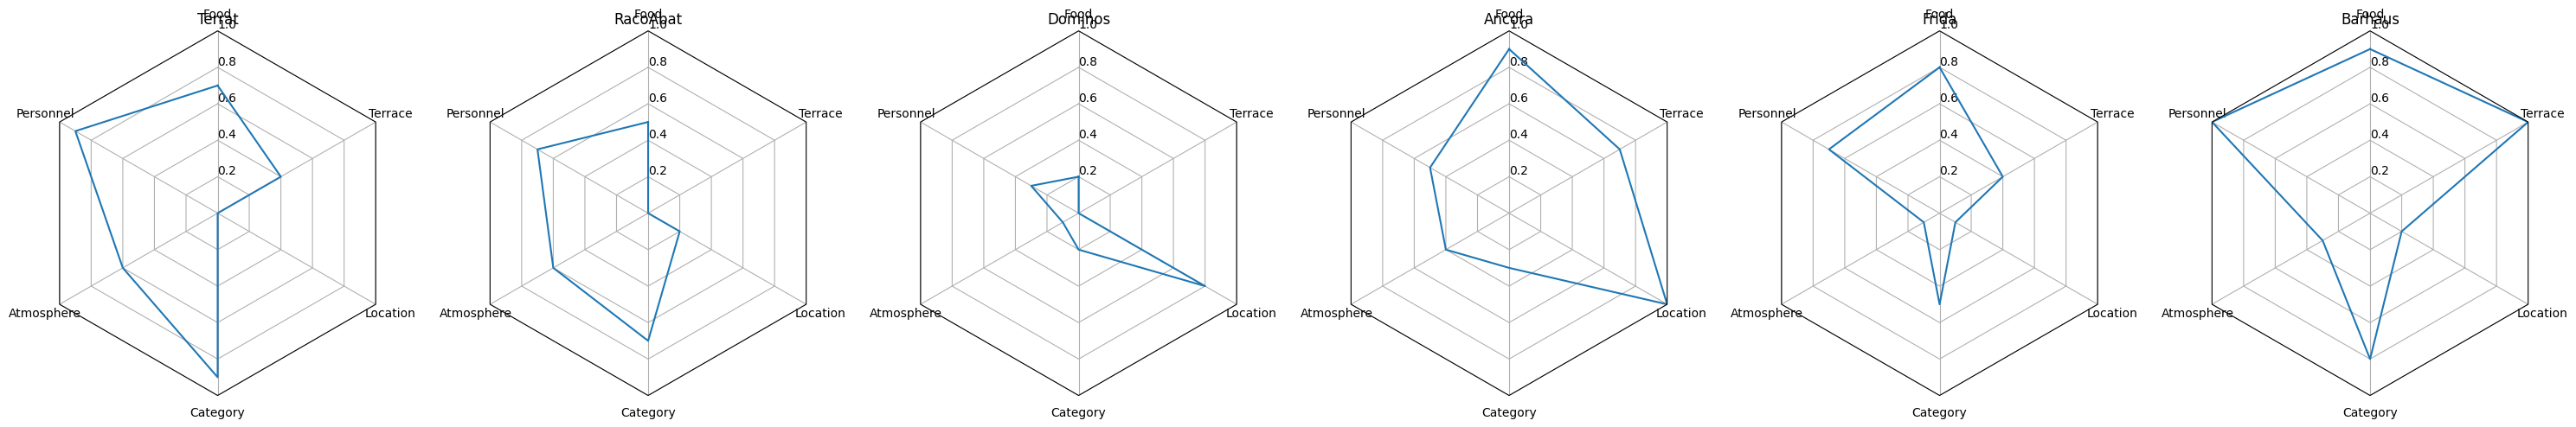

In [34]:
create_radar_projection(len(criteria), frame='polygon')

fig = Figure(ncols=6, figsize=(30, 30))

for alternative in alternatives:
    values = performance_table.get_alternative_values(alternative)
    ax = fig.create_add_axis(projection = radar_projection_name(len(criteria.values())))

    ax.title = alternative
    ax.title_pad = 100
    ax.add_plot(
        RadarPlot(
            list(criteria.keys()),
            values.data,
            rlimits = [0,1]
        )
    )

fig.draw()

3. Now we want to apply the WSM aggregation. First, we will multiply the utilities and the corresponding weight.

In [35]:
weighted_table = performance_table.apply_criteria_weights(criteria)

weighted_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.21,0.27,0.06,0.09,0.00,0.04
RacoAbat,0.15,0.21,0.06,0.07,0.02,0.00
Dominos,0.06,0.09,0.01,0.02,0.08,0.00
Ancora,0.27,0.15,0.04,0.03,0.10,0.07
Frida,0.24,0.21,0.01,0.05,0.01,0.04
Barhaus,0.27,0.30,0.03,0.08,0.02,0.10


4. Secondly, we sum up all the alternatives to obtain an overall score on each one.

In [36]:
utilitiesWM = weighted_table.sum(axis=1)
utilitiesWM

,0
Terrat,0.67
RacoAbat,0.51
Dominos,0.26
Ancora,0.66
Frida,0.56
Barhaus,0.80


5. Once we have obtained the weighed table, let's plot it to see visually which alternative is the best according to the specified criteria weights.

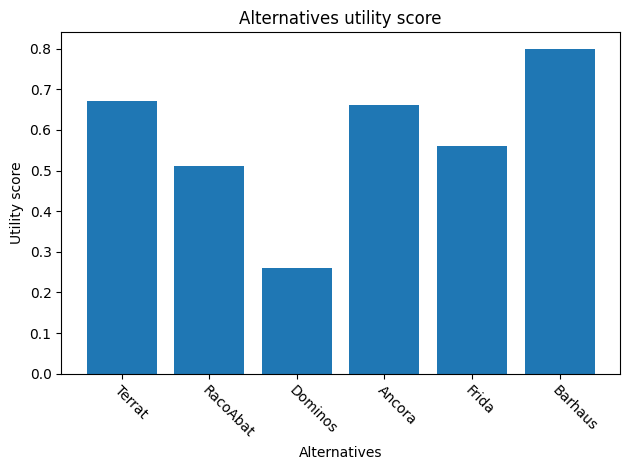

In [37]:
x = [*range(len(alternatives))]

plot = BarPlot(
    x, utilitiesWM, xticks=x,
    xticklabels = alternatives, xticklabels_tilted = True
)
plot.draw()
plot.axis.title = "Alternatives utility score"
plot.axis.xlabel = "Alternatives"
plot.axis.ylabel = "Utility score"
plot.axis.figure.draw()

*According to this plot, which alternative do you think is the best? Why?*

*Notice that in this representation you can discard visually which are the worst alternatives.*

## Task 2: **Add new alternatives**

6. Modify the dataset including two new alternatives with the following characteristics:
- A restaurant that has the worst evaluations in all the criteria except in Service.
- A restaurant that has the worst evaluations in all the criteria except in Location.

Apply again the WSM and study the results achieved for these new restaurants in comparison with the rest of restaurants. Take into account that you must modify also the *alternatives* array.

In [38]:
# Alternatives names
new_alternatives = ["Restaurante BARMUT", "McDonalds"]

# Alternatives scores for each criterion
alternatives_values = {
    "Food": [0.2, 0.3],
    "Personnel": [0.9, 0.3],  # Good Service (Personnel) for Restaurante BARMUT
    "Atmosphere": [0.3, 0.4],
    "Category": [0.2, 0.3],
    "Location": [0.3, 0.9],  # Good location for McDonalds
    "Terrace": [0.3, 0.4]
}

Now, modify the performance table by adding the utilities as indicated. You can also represent them in radar (spider) graphics if you want.

In [39]:
all_alternatives = alternatives + new_alternatives

performance_table.df = pd.concat([
    performance_table.df,
    pd.DataFrame(alternatives_values, index = new_alternatives)],
    axis = 0)
performance_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.7,0.9,0.6,0.9,0.0,0.4
RacoAbat,0.5,0.7,0.6,0.7,0.2,0.0
Dominos,0.2,0.3,0.1,0.2,0.8,0.0
Ancora,0.9,0.5,0.4,0.3,1.0,0.7
Frida,0.8,0.7,0.1,0.5,0.1,0.4
Barhaus,0.9,1.0,0.3,0.8,0.2,1.0
Restaurante BARMUT,0.2,0.9,0.3,0.2,0.3,0.3
McDonalds,0.3,0.3,0.4,0.3,0.9,0.4


Repeat the steps of the first part of the exercise to calculate the Weigthed Average and plot the results.

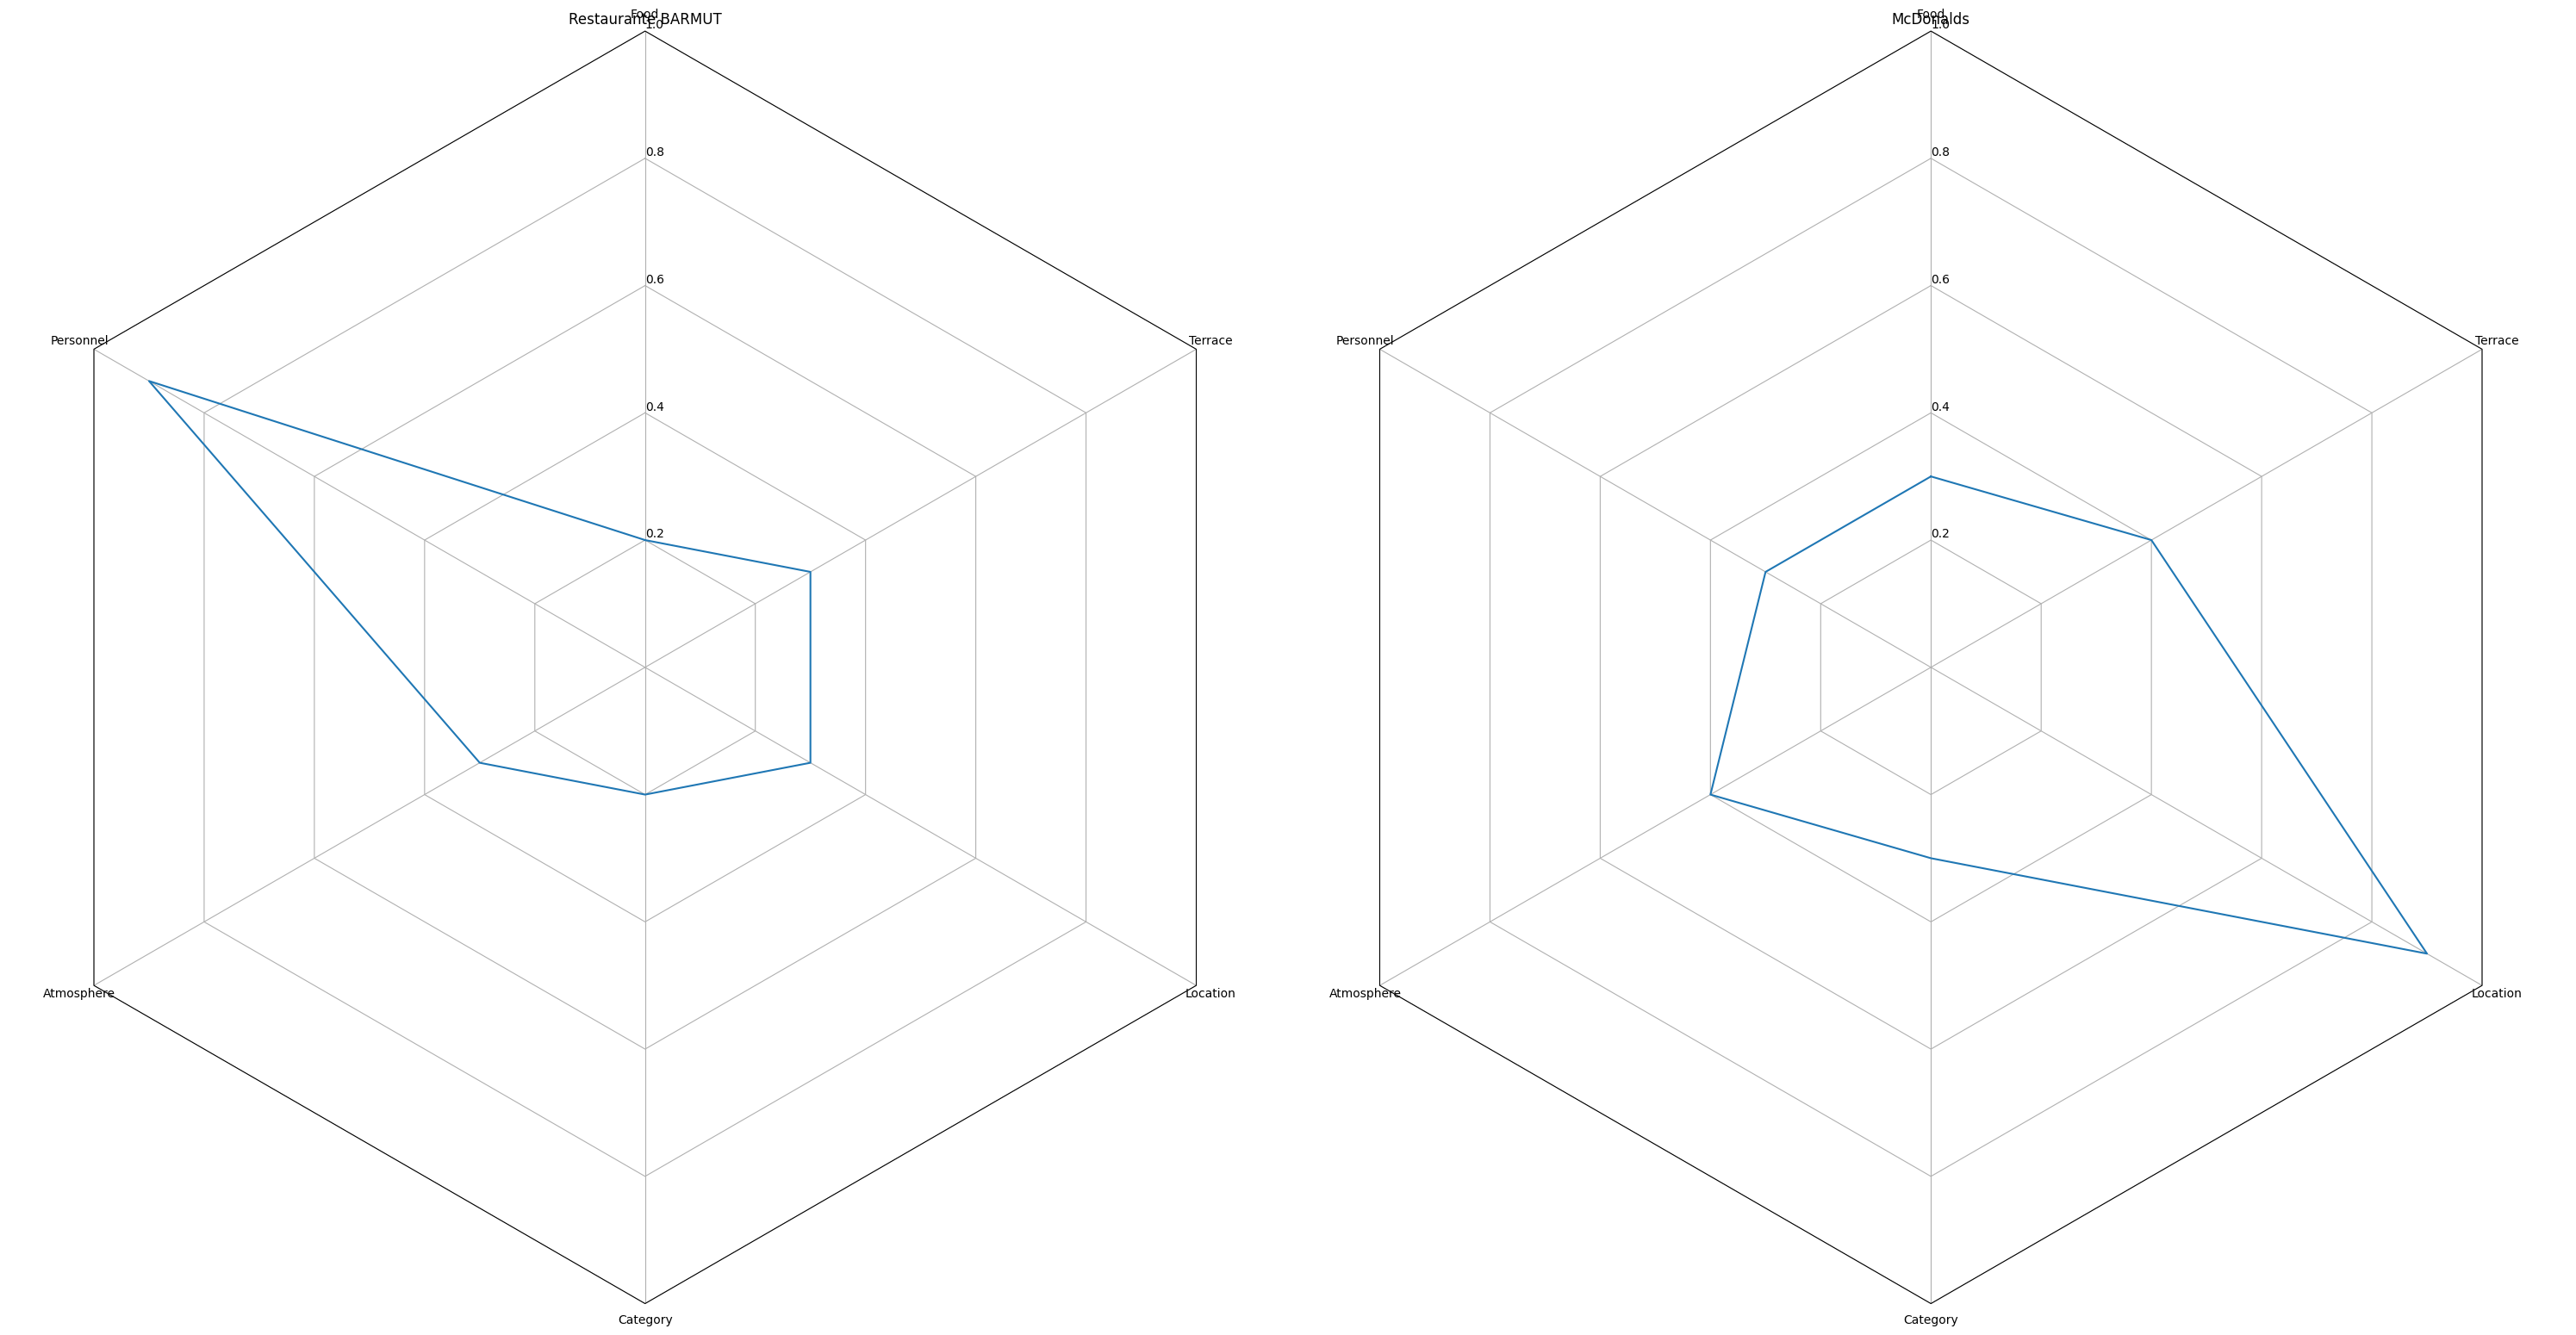

In [40]:
create_radar_projection(len(criteria), frame='polygon')

fig = Figure(ncols=2, figsize=(30, 30))

for alternative in all_alternatives[6:]:
    values = performance_table.get_alternative_values(alternative)
    ax = fig.create_add_axis(projection = radar_projection_name(len(criteria.values())))

    ax.title = alternative
    ax.title_pad = 100
    ax.add_plot(
        RadarPlot(
            list(criteria.keys()),
            values.data,
            rlimits = [0,1]
        )
    )

fig.draw()

In [41]:
weighted_table = performance_table.apply_criteria_weights(criteria)
weighted_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.21,0.27,0.06,0.09,0.00,0.04
RacoAbat,0.15,0.21,0.06,0.07,0.02,0.00
Dominos,0.06,0.09,0.01,0.02,0.08,0.00
Ancora,0.27,0.15,0.04,0.03,0.10,0.07
Frida,0.24,0.21,0.01,0.05,0.01,0.04
Barhaus,0.27,0.30,0.03,0.08,0.02,0.10
Restaurante BARMUT,0.06,0.27,0.03,0.02,0.03,0.03
McDonalds,0.09,0.09,0.04,0.03,0.09,0.04


In [42]:
utilitiesWM = weighted_table.sum(axis=1)
utilitiesWM

,0
Terrat,0.67
RacoAbat,0.51
Dominos,0.26
Ancora,0.66
Frida,0.56
Barhaus,0.80
Restaurante BARMUT,0.44
McDonalds,0.38


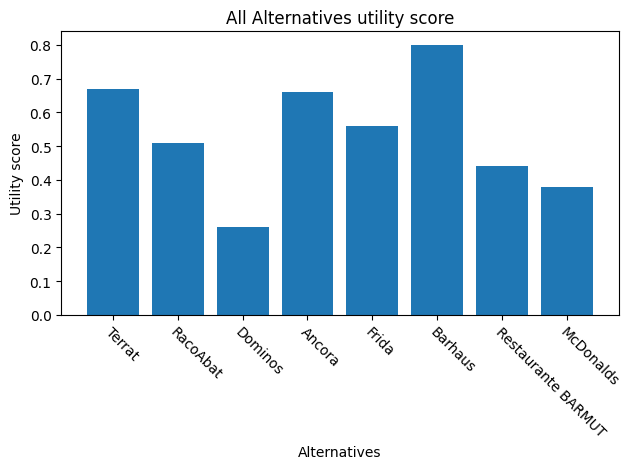

In [43]:
x = [*range(len(all_alternatives))]

plot = BarPlot(
    x, utilitiesWM, xticks=x,
    xticklabels = all_alternatives, xticklabels_tilted = True
)
plot.draw()
plot.axis.title = "All Alternatives utility score"
plot.axis.xlabel = "Alternatives"
plot.axis.ylabel = "Utility score"
plot.axis.figure.draw()

## Task 3: **arithmetic non-weighted average**

In this part, you will execute a non-weighted **Arithmetic average**. Thus, it is necessary to modify the criteria weights by establishing the same weights for all criteria.

In [44]:
criteria_task3 = {
    "Food": 1 / 6,
    "Personnel": 1 / 6,
    "Atmosphere": 1 / 6,
    "Category": 1 / 6,
    "Location": 1 / 6,
    "Terrace": 1 / 6
}
criteria_task3

{'Food': 0.16666666666666666,
 'Personnel': 0.16666666666666666,
 'Atmosphere': 0.16666666666666666,
 'Category': 0.16666666666666666,
 'Location': 0.16666666666666666,
 'Terrace': 0.16666666666666666}

Now, follow the same steps as in part one to calculate the Weigthed Average and plot the results.

In [45]:
weighted_table = performance_table.apply_criteria_weights(criteria_task3)
weighted_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.116667,0.150000,0.100000,0.150000,0.000000,0.066667
RacoAbat,0.083333,0.116667,0.100000,0.116667,0.033333,0.000000
Dominos,0.033333,0.050000,0.016667,0.033333,0.133333,0.000000
Ancora,0.150000,0.083333,0.066667,0.050000,0.166667,0.116667
Frida,0.133333,0.116667,0.016667,0.083333,0.016667,0.066667
Barhaus,0.150000,0.166667,0.050000,0.133333,0.033333,0.166667
Restaurante BARMUT,0.033333,0.150000,0.050000,0.033333,0.050000,0.050000
McDonalds,0.050000,0.050000,0.066667,0.050000,0.150000,0.066667


In [46]:
utilitiesWM_task3 = weighted_table.sum(axis=1)
utilitiesWM

,0
Terrat,0.67
RacoAbat,0.51
Dominos,0.26
Ancora,0.66
Frida,0.56
Barhaus,0.80
Restaurante BARMUT,0.44
McDonalds,0.38


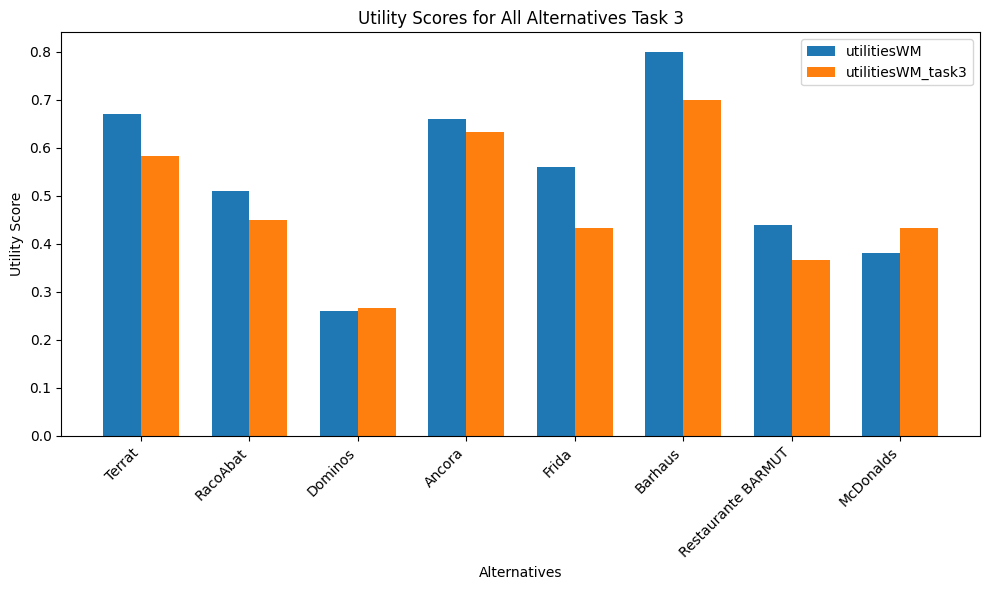

In [47]:
x = np.arange(len(all_alternatives))
bar_width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))

# Plot utilitiesWM and utilitiesWM_task3
bar1 = ax.bar(x - bar_width / 2, utilitiesWM, bar_width, label="utilitiesWM")
bar2 = ax.bar(x + bar_width / 2, utilitiesWM_task3, bar_width, label="utilitiesWM_task3")

# Set labels, title, and axis labels
ax.set_xlabel("Alternatives")
ax.set_ylabel("Utility Score")
ax.set_title("Utility Scores for All Alternatives Task 3")
ax.set_xticks(x)
ax.set_xticklabels(all_alternatives, rotation=45, ha="right")
ax.legend()

# Show the plot
plt.tight_layout()
plt.show()

## Task 4: **OWA operator**

Now we will study the Ordered Weighted Average, with the same case study.
First we must import the functions about OWA from the package.

In [48]:
from mcda.mavt.aggregators import *
from mcda.core.scales import *


7. Rember that OWA does not give weights to criteria, so we assume all criteria have the same importance. We have now to define a set of weights that establish the aggregation policy (from a conjunctive to a disjunctive model).
The weights will be applied to the values after reordering them decreasingly.

You have here a set of weights to use as a first example. Can you say which is the aggregation policy?

In [49]:
weightsOWA =  [0.1, 0.3, 0.6, 0.0, 0.0, 0.0]
weightsOWA

[0.1, 0.3, 0.6, 0.0, 0.0, 0.0]

In [50]:
performance_table = PerformanceTable(
    [[0.7, 0.9, 0.6, 0.9, 0.0, 0.4],
     [0.5, 0.7, 0.6, 0.7, 0.2, 0.0],
     [0.2, 0.3, 0.1, 0.2, 0.8, 0.0],
     [0.9, 0.5, 0.4, 0.3, 1.0, 0.7],
     [0.8, 0.7, 0.1, 0.5, 0.1, 0.4],
     [0.9, 1.0, 0.3, 0.8, 0.2, 1.0]],
    alternatives = alternatives,
    criteria = criteria.keys())

performance_table.df

,Food,Personnel,Atmosphere,Category,Location,Terrace
Terrat,0.7,0.9,0.6,0.9,0.0,0.4
RacoAbat,0.5,0.7,0.6,0.7,0.2,0.0
Dominos,0.2,0.3,0.1,0.2,0.8,0.0
Ancora,0.9,0.5,0.4,0.3,1.0,0.7
Frida,0.8,0.7,0.1,0.5,0.1,0.4
Barhaus,0.9,1.0,0.3,0.8,0.2,1.0


In [51]:
owa = OWA(weightsOWA)
utilitiesOWA = owa(performance_table)
utilitiesOWA

,0
Terrat,0.78
RacoAbat,0.64
Dominos,0.29
Ancora,0.79
Frida,0.59
Barhaus,0.94


8. You should  also represent the scores obtained with the bar plot to facilitate the visualization.

[Text(0, 0, 'Terrat'),
 Text(1, 0, 'RacoAbat'),
 Text(2, 0, 'Dominos'),
 Text(3, 0, 'Ancora'),
 Text(4, 0, 'Frida'),
 Text(5, 0, 'Barhaus')]

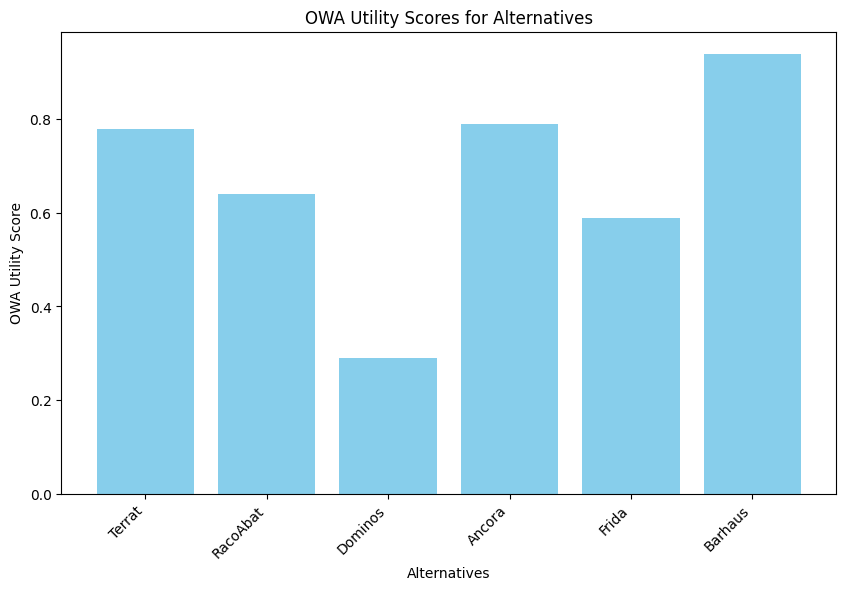

In [52]:
# Create a bar plot to represent the OWA utilities
x = np.arange(len(alternatives))
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the bar chart
ax.bar(x, utilitiesOWA, color='skyblue')

# Set labels and title
ax.set_xlabel("Alternatives")
ax.set_ylabel("OWA Utility Score")
ax.set_title("OWA Utility Scores for Alternatives")
ax.set_xticks(x)
ax.set_xticklabels(alternatives, rotation=45, ha="right")

9. Now, we will compare different sets of OWA weights. First you must define a disjunctive (OR) policy (with a weight=0 for the 2 worst values). Apply it to the restaurants.

10. Second, you must establish a conjunctive (AND) policy (simultaneity is required, most of the criteria must be fulfilled). Apply it to the restaurants.

11. Compare the results of both aggregation policies. Compare also them with respect to the arithmetic average.

In [53]:
# Define disjunctive policy (weights = 0 for the two worst values)
weights_disjunctive = [0.3, 0.3, 0.2, 0.2, 0.0, 0.0]

# Apply the disjunctive OWA operator
owa_disjunctive = OWA(weights_disjunctive)
utilities_disjunctive = owa_disjunctive(performance_table)

# Print the OWA utilities for the disjunctive policy
print("Disjunctive Policy Utility Scores:")
for alternative, utility in zip(alternatives, utilities_disjunctive):
    print(f"{alternative}: {utility:.2f}")


Disjunctive Policy Utility Scores:
Terrat: 0.80
RacoAbat: 0.64
Dominos: 0.41
Ancora: 0.81
Frida: 0.63
Barhaus: 0.94


In [54]:
# Define conjunctive policy
weights_conjunctive = [0.2, 0.2, 0.2, 0.2, 0.1, 0.1]

# Apply the conjunctive OWA operator
owa_conjunctive = OWA(weights_conjunctive)
utilities_conjunctive = owa_conjunctive(performance_table)

# Print the OWA utilities for the conjunctive policy
print("Conjunctive Policy Utility Scores:")
for alternative, utility in zip(alternatives, utilities_conjunctive):
    print(f"{alternative}: {utility:.2f}")


Conjunctive Policy Utility Scores:
Terrat: 0.66
RacoAbat: 0.52
Dominos: 0.31
Ancora: 0.69
Frida: 0.50
Barhaus: 0.79


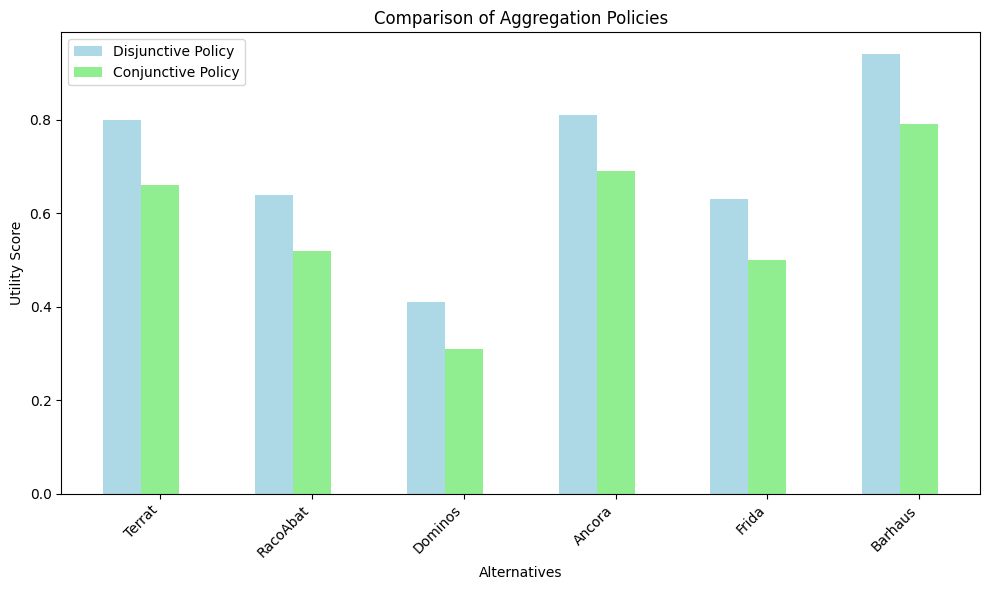

In [55]:
# Define the positions for the bar plot
x = np.arange(len(alternatives))

# Create the figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the results for each policy
width = 0.25  # width of bars for each policy
ax.bar(x - width, utilities_disjunctive, width, label='Disjunctive Policy', color='lightblue')
ax.bar(x, utilities_conjunctive, width, label='Conjunctive Policy', color='lightgreen')

# Add labels and title
ax.set_xlabel("Alternatives")
ax.set_ylabel("Utility Score")
ax.set_title("Comparison of Aggregation Policies")
ax.set_xticks(x)
ax.set_xticklabels(alternatives, rotation=45, ha="right")
ax.legend()

# Show the plot
plt.tight_layout()
plt.show()

## Task 5 **Aggregation policies: descriptors of the OWA weights**

There are different measures to characterise the vector of weights, such as: Balance, Divergence, Entropy and Orness.

In this task, we will practise with the examples of sets of weights given in the following table:

| Weights | Balance | Divergence | Entropy| Orness |
| --- | --- | --- | --- | --- |
| 0.0, 0.3, 0.4, 0.3, 0.0, 0.0 | - | - | - | - |
| 0.0, 0.0, 0.0, 0.2, 0.3, 0.5 | - | - | - | - |
| 1.0, 0.0, 0.0, 0.0, 0.0, 0.0 | - | - | - | - |
| 0.1, 0.1, 0.3, 0.3, 0.1, 0.1 | - | - | - | - |
| 0.1, 0.3, 0.6, 0.0, 0.0, 0.0 | - | - | - | - |

12. The MCDA package only includes the orness and dispersion measures, for the moment. So, below you have the functions that implement the characterisation measures of OWA weights. The input of these functions is a vector of weights. So they must be executed for each row of the table.

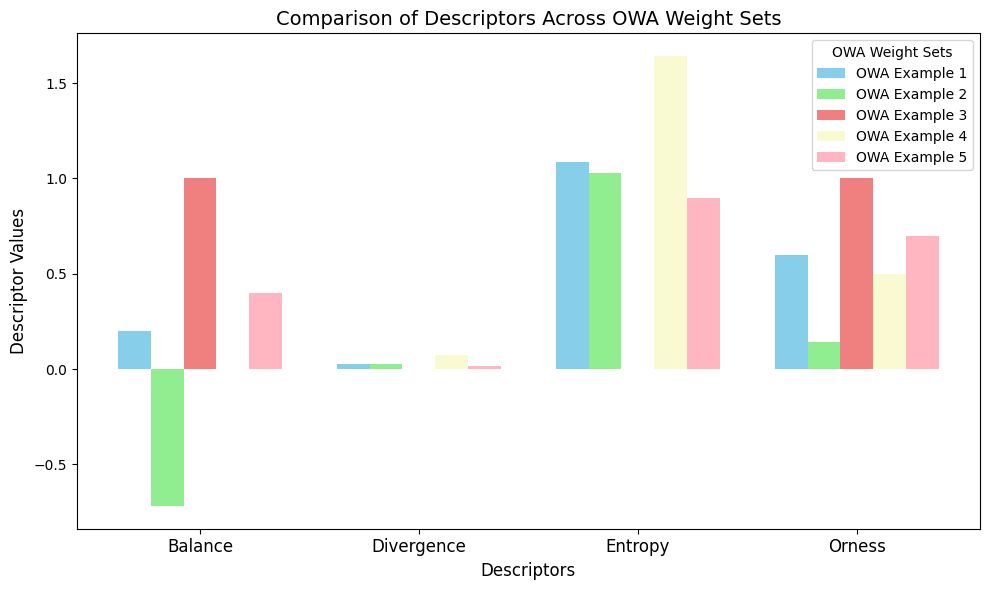

In [56]:
import matplotlib.pyplot as plt
import numpy as np
from mcda.mavt.aggregators import OWA

examples_OWA_weights = [
    [0.0, 0.3, 0.4, 0.3, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.2, 0.3, 0.5],
    [1.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.1, 0.1, 0.3, 0.3, 0.1, 0.1],
    [0.1, 0.3, 0.6, 0.0, 0.0, 0.0]
]

balance_values = []
divergence_values = []
entropy_values = []
orness_values = []

# Calculate descriptors for each set of OWA weights
for weights in examples_OWA_weights:
    example_OWA = OWA(weights)
    balance_values.append(example_OWA.balance)
    divergence_values.append(example_OWA.divergence)
    entropy_values.append(example_OWA.dispersion)
    orness_values.append(example_OWA.orness)

# Data for plotting
descriptors = ['Balance', 'Divergence', 'Entropy', 'Orness']
data = np.array([balance_values, divergence_values, entropy_values, orness_values]).T
colors = ['skyblue', 'lightgreen', 'lightcoral', 'lightgoldenrodyellow', 'lightpink']

fig, ax = plt.subplots(figsize=(10, 6))
n_descriptors = len(descriptors)
n_examples = len(examples_OWA_weights)

bar_width = 0.15
index = np.arange(n_descriptors)

# Create a bar for each OWA weight set, each descriptor
for i in range(n_examples):
    ax.bar(index + i * bar_width, data[i], bar_width, label=f"OWA Example {i+1}", color=colors[i])

# Adding labels and title
ax.set_xlabel('Descriptors', fontsize=12)
ax.set_ylabel('Descriptor Values', fontsize=12)
ax.set_title('Comparison of Descriptors Across OWA Weight Sets', fontsize=14)
ax.set_xticks(index + bar_width * (n_examples - 1) / 2)
ax.set_xticklabels(descriptors, fontsize=12)

# Add legend
ax.legend(title='OWA Weight Sets')

# Display the plot
plt.tight_layout()
plt.show()

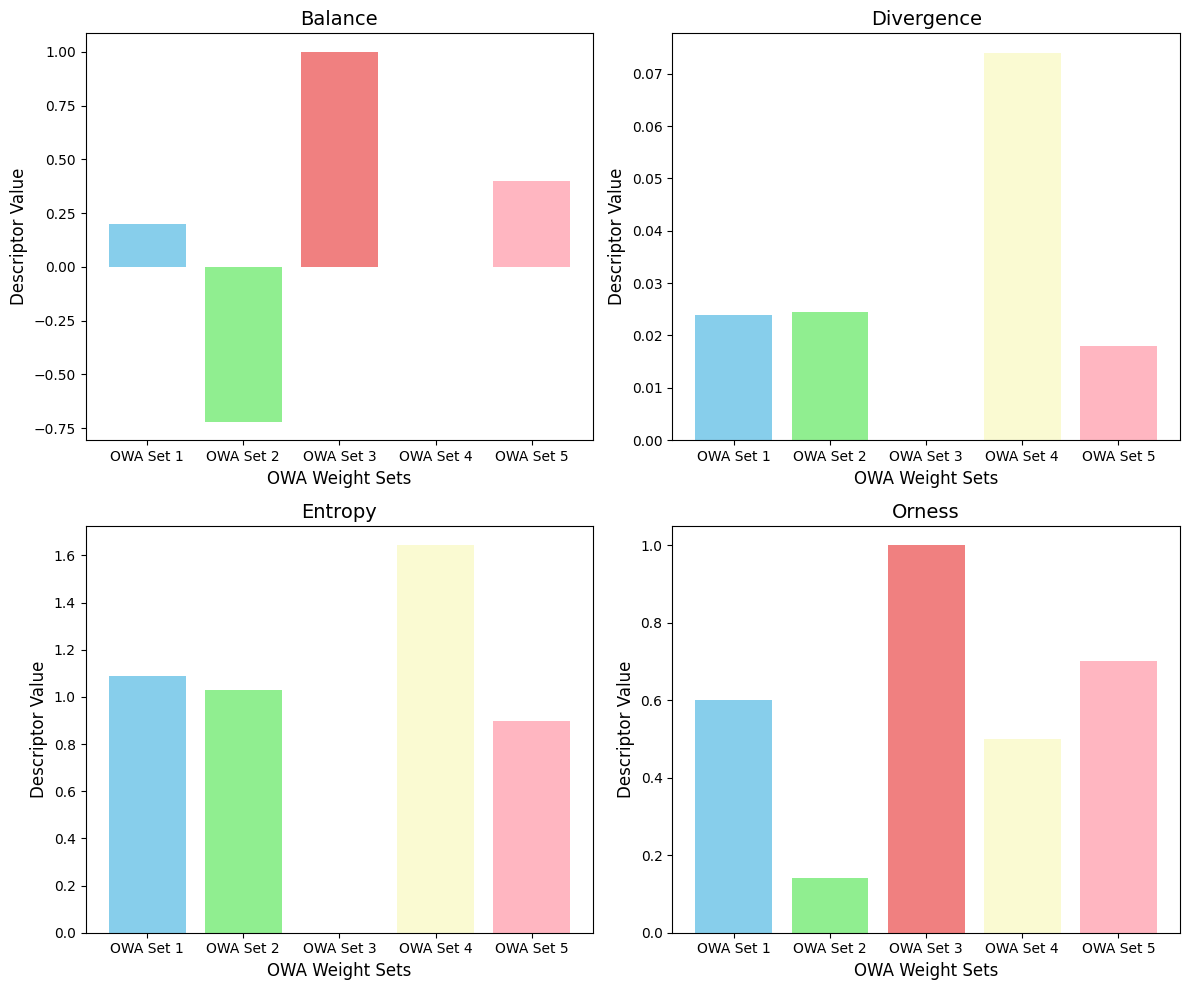

In [57]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

metrics = [balance_values, divergence_values, entropy_values, orness_values]
metric_names = ['Balance', 'Divergence', 'Entropy', 'Orness']
colors = ['skyblue', 'lightgreen', 'lightcoral', 'lightgoldenrodyellow', 'lightpink']

for i, ax in enumerate(axs.flat):
    ax.bar(np.arange(n_examples), metrics[i], color=colors[:n_examples])
    ax.set_title(metric_names[i], fontsize=14)
    ax.set_xlabel('OWA Weight Sets', fontsize=12)
    ax.set_ylabel('Descriptor Value', fontsize=12)
    ax.set_xticks(np.arange(n_examples))
    ax.set_xticklabels([f'OWA Set {i+1}' for i in range(n_examples)], fontsize=10)

# Adjust the layout for better spacing
plt.tight_layout()

# Display the plot
plt.show()

{'OWA Weight Set': ['OWA Example 1', 'OWA Example 2', 'OWA Example 3', 'OWA Example 4', 'OWA Example 5'], 'Weights': ['[0.0, 0.3, 0.4, 0.3, 0.0, 0.0]', '[0.0, 0.0, 0.0, 0.2, 0.3, 0.5]', '[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]', '[0.1, 0.1, 0.3, 0.3, 0.1, 0.1]', '[0.1, 0.3, 0.6, 0.0, 0.0, 0.0]'], 'Balance': [0.2, -0.72, 1.0, 0.0, 0.4], 'Divergence': [0.024, 0.0244, 0.0, 0.074, 0.018000000000000002], 'Entropy': [1.0888999753452238, 1.0296530140645737, -0.0, 1.6434177197931796, 0.8979457248567797], 'Orness': [0.6000000000000001, 0.13999999999999999, 1.0, 0.5, 0.7]}
5
5
5
5


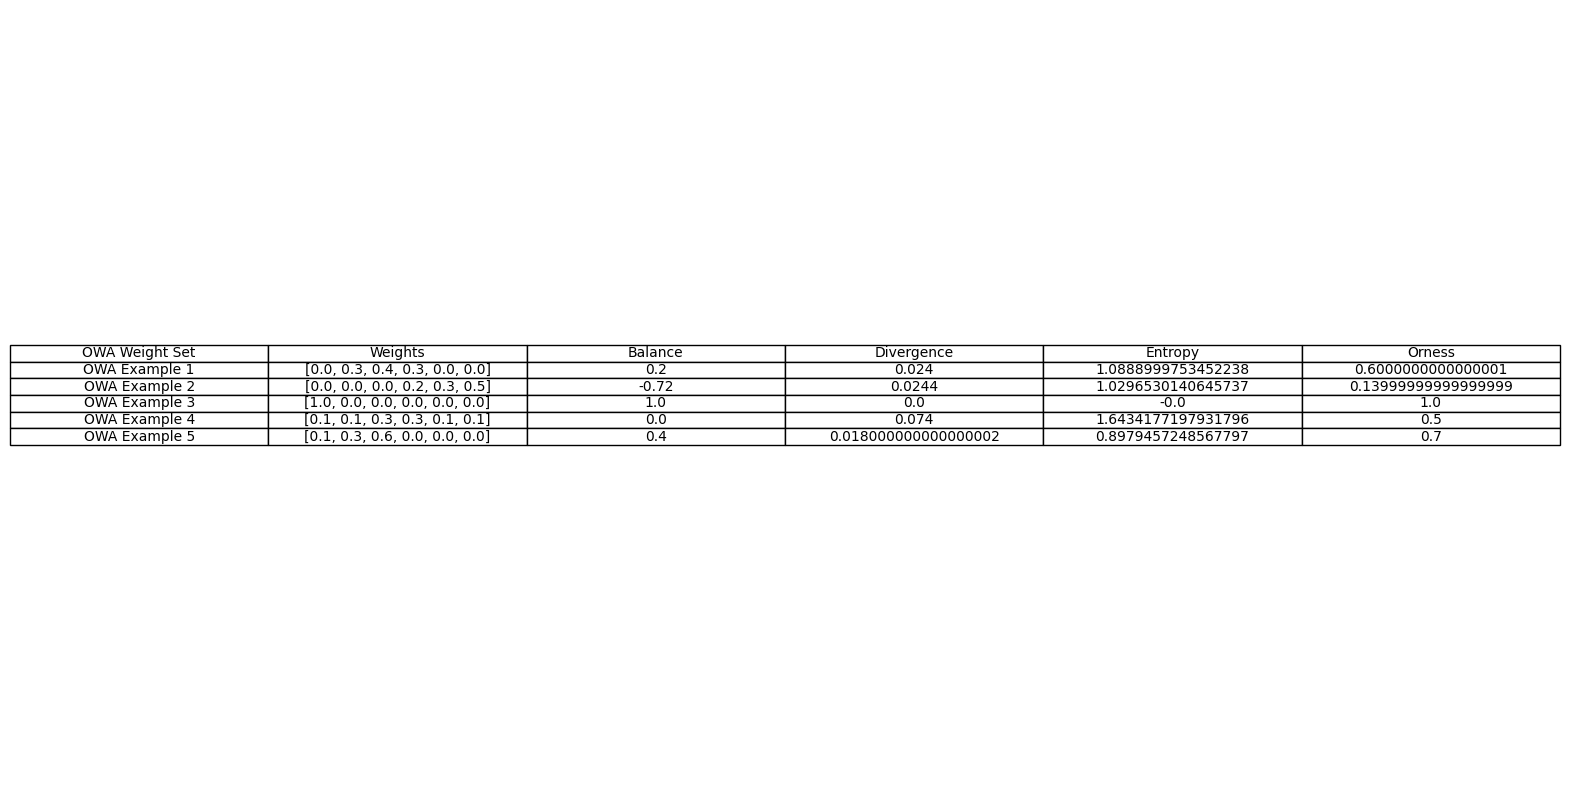

,OWA Weight Set,Weights,Balance,Divergence,Entropy,Orness
0,OWA Example 1,"[0.0, 0.3, 0.4, 0.3, 0.0, 0.0]",0.20,0.0240,1.088900,0.60
1,OWA Example 2,"[0.0, 0.0, 0.0, 0.2, 0.3, 0.5]",-0.72,0.0244,1.029653,0.14
2,OWA Example 3,"[1.0, 0.0, 0.0, 0.0, 0.0, 0.0]",1.00,0.0000,-0.000000,1.00
3,OWA Example 4,"[0.1, 0.1, 0.3, 0.3, 0.1, 0.1]",0.00,0.0740,1.643418,0.50
4,OWA Example 5,"[0.1, 0.3, 0.6, 0.0, 0.0, 0.0]",0.40,0.0180,0.897946,0.70


In [58]:
balance_values = []
divergence_values = []
entropy_values = []
orness_values = []

# Calculate descriptors for each set of OWA weights
for weights in examples_OWA_weights:
    example_OWA = OWA(weights)
    balance_values.append(example_OWA.balance)
    divergence_values.append(example_OWA.divergence)
    entropy_values.append(example_OWA.dispersion)
    orness_values.append(example_OWA.orness)

n = len(examples_OWA_weights)

# Creating a DataFrame to hold all the values
data_dict = {
    'OWA Weight Set': [f'OWA Example {i+1}' for i in range(n)],
    'Weights': [str(weights) for weights in examples_OWA_weights],
    'Balance': balance_values,
    'Divergence': divergence_values,
    'Entropy': entropy_values,
    'Orness': orness_values
}
print(data_dict)
print(len(balance_values))
print(len(divergence_values))
print(len(entropy_values))
print(len(orness_values))

# Create DataFrame
df = pd.DataFrame(data_dict)

# Display the DataFrame as a table in matplotlib
fig, ax = plt.subplots(figsize=(20, 10))
ax.axis('tight')
ax.axis('off')
ax.table(cellText=df.values, colLabels=df.columns, cellLoc='center', loc='center')

# Display the table
plt.show()
df.head()